# Household Energy Trajectories: unsupervised learning on 29,000 English and Welsh homes
## AI Methods I – Day 3: Unsupervised learning (IAAC MaAI 2026/27) · Group 4

**Team:** Group 4 – Luis, Fawad, Hetashri, Daria

On Day 2 we **predicted** how much gas a home will use in 2024. Today there is no target. We ask a different question about the same homes:

> ***Which kinds of household energy behaviour exist, and how did they evolve over 20 years?***

### Use case
**Who:** a local authority or energy-efficiency programme (for example a council planning a retrofit and fuel-poverty scheme).
**For what:** to decide **which households to contact first**. A home that still uses a lot of gas and never reduced it is a better retrofit candidate than one that already cut its demand. A home that cut its gas sharply during the 2022 price crisis might be *under-heating* rather than efficient, which is a fuel-poverty signal.
**What makes a group useful:** we can **name** it in one line (e.g. *"high users that never reduced"*), and it points to an **action** (insulate, check for fuel poverty, no action needed).

### The three steps of this notebook

| Step | Methods | Question |
|---|---|---|
| **1. Dimensionality reduction** | PCA, t-SNE, UMAP | How many real directions of variation do our features have? Can we *see* the data in 2D? |
| **2. Clustering** | K-Means, hierarchical (Ward), DBSCAN | Which groups exist? How many? Do the algorithms agree? Are the groups stable? |
| **3. Application: energy typologies** | Profiles, cross-tabs, naming | What does each group mean for a retrofit programme? |

### Contents
0. Setup and data · 1. Features and preprocessing · 2. Dimensionality reduction · 3. Clustering · 4. Stability · 5. Interpretation and naming · 6. Save and reuse the model · 7. Export the clustered dataset · 8. Conclusions

# 0. Setup and data

In [1]:
# Only needed in a new environment: remove the "#" and run once.
# %pip install pandas numpy matplotlib seaborn scikit-learn scipy umap-learn joblib

In [2]:
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram
import umap

# --- Folders (the notebook lives in notebook/, the other folders are one level up) ---
DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
DATASET_DIR = Path("..") / "dataset"
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR, DATASET_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
INK, MUTED_INK, GRID = "#1F2933", "#5B646E", "#E4E7EB"
ACCENT = "#1F6F78"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.edgecolor": GRID, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.labelcolor": MUTED_INK, "xtick.color": MUTED_INK, "ytick.color": MUTED_INK})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)


def save(fig_name):
    # Export the current figure to figures/ (the README and the cards embed these files)
    plt.savefig(FIG_DIR / fig_name, dpi=150, bbox_inches="tight")

### Load the data
We start from the **cleaned dataset of our Day 1 / Day 2 assignment**: a 50,000-home sample of the UK government's **National Energy Efficiency Data-Framework (NEED)** anonymised dataset. If the file is not in `data/` yet, it is downloaded from our Day 2 repository.

In [3]:
DATA_URL = ("https://raw.githubusercontent.com/iaac-maai/Group4-day2-assignment/"
            "refs/heads/main/data/anon2026_50k_cleaned.csv")
data_path = DATA_DIR / "anon2026_50k_cleaned.csv"
if not data_path.exists():
    urllib.request.urlretrieve(DATA_URL, data_path)

homes = pd.read_csv(data_path)
print(f"{homes.shape[0]:,} homes x {homes.shape[1]} columns")
homes.iloc[:3, :16]

49,998 homes x 96 columns


,PROP_TYPE,PROP_AGE_BAND,FLOOR_AREA_BAND,CONSERVATORY_FLAG,COUNCIL_TAX_BAND,IMD_BAND_ENG,IMD_BAND_WALES,REGION,EPC,LI_FLAG,LI_DATE,CWI_FLAG,CWI_DATE,PV_FLAG,PV_DATE,MAIN_HEAT_FUEL
0,Semi detached,3,2,NaN,A,3.0,NaN,E12000004,C,0,NaN,0,NaN,0,NaN,1
1,Mid terrace,1,3,NaN,E,1.0,NaN,E12000007,No EPC,0,NaN,0,NaN,0,NaN,1
2,Detached,4,3,0.0,E,3.0,NaN,E12000005,A/B,0,NaN,0,NaN,0,NaN,1


**What is in the table** (codes from the NEED documentation):

| Columns | Content |
|---|---|
| `PROP_TYPE`, `PROP_AGE_BAND`, `FLOOR_AREA_BAND` | Dwelling type; age band (1 = oldest … 4 = newest); floor-area band (1 = smallest … 5 = largest) |
| `COUNCIL_TAX_BAND`, `IMD_BAND_ENG` / `_WALES` | Property-value band (A = lowest); deprivation quintile of the area (1 = most deprived) |
| `REGION`, `EPC` | Region (ONS code); Energy Performance Certificate band |
| `CWI_FLAG`, `LI_FLAG`, `PV_FLAG` (+ `_DATE`) | Cavity-wall insulation, loft insulation, solar PV installed (and when) |
| `MAIN_HEAT_FUEL` | 1 = gas, 2 = other fuel |
| `Gcons2005` … `Gcons2024`, `Econs2005` … `Econs2024` | **Annual gas and electricity consumption** (kWh), 20 years |
| `GasValFlag…`, `ElecValFlag…` | Quality flag of each reading: **`V` = valid**; other codes mark readings outside the validity rules |

**Unit of analysis: one home.** Each home has up to 40 yearly meter readings. We summarise them into a few behaviour features (section 1).

In [4]:
REGION_NAMES = {"E12000001": "North East", "E12000002": "North West", "E12000003": "Yorkshire & Humber",
                "E12000004": "East Midlands", "E12000005": "West Midlands", "E12000006": "East of England",
                "E12000007": "London", "E12000008": "South East", "E12000009": "South West",
                "W92000004": "Wales"}
homes["region_name"] = homes["REGION"].map(REGION_NAMES)
homes["imd_band"] = homes["IMD_BAND_ENG"].fillna(homes["IMD_BAND_WALES"])   # one deprivation column for both nations

print(homes["MAIN_HEAT_FUEL"].value_counts().rename({1: "gas", 2: "other fuel"}))

MAIN_HEAT_FUEL
gas           40445
other fuel     9553
Name: count, dtype: int64


# 1. Features and preprocessing

## 1.1 Which homes?
We keep the **gas-heated homes** (`MAIN_HEAT_FUEL == 1`): for the 9,553 homes heated by other fuels the gas columns are empty, and their heating demand is hidden inside the electricity reading, so they are not comparable. They would need their own analysis.

We use **only readings flagged `V` (valid)**. A reading flagged otherwise (estimated, outside the plausible range…) is set to missing.

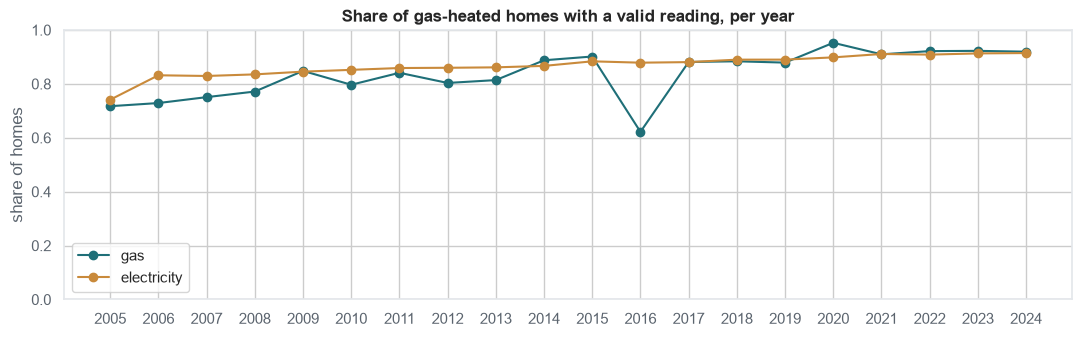

In [5]:
YEARS = list(range(2005, 2025))
gas_homes = homes[homes["MAIN_HEAT_FUEL"] == 1].copy()

gas = pd.DataFrame({y: gas_homes[f"Gcons{y}"].where(gas_homes[f"GasValFlag{y}"] == "V") for y in YEARS})
elec = pd.DataFrame({y: gas_homes[f"Econs{y}"].where(gas_homes[f"ElecValFlag{y}"] == "V") for y in YEARS})

valid_share = pd.DataFrame({"gas": gas.notna().mean(), "electricity": elec.notna().mean()})
ax = valid_share.plot(figsize=(13, 3.5), marker="o", color=[ACCENT, "#C98A3B"])
ax.set_title("Share of gas-heated homes with a valid reading, per year")
ax.set_ylabel("share of homes")
ax.set_ylim(0, 1)
ax.set_xticks(YEARS)
plt.show()

Coverage grows over time (more meters enter the sample), and 2016 has fewer valid gas readings than its neighbours (many readings flagged as estimated that year). Single years are therefore noisy. That is why we will average **windows of several years** rather than use one year.

## 1.2 Engineered features: level and trajectory
We want "similar" to mean **similar energy behaviour today *and* a similar history**, because that is what a retrofit programme acts on. We therefore build five features from three time windows:

| Window | Years | Represents |
|---|---|---|
| **early** | 2005–2008 | the starting point, before most insulation programmes |
| **pre-crisis** | 2019–2021 | the state just before the energy-price crisis |
| **recent** | 2022–2024 | after the price shock of 2022 |

A window counts only if it has **at least 2 valid readings**.

| Feature (clustered on) | Formula | Meaning |
|---|---|---|
| `log_gas_recent` | log10(mean gas 2022–24) | **How much gas** the home uses now (≈ heating demand) |
| `log_elec_recent` | log10(mean electricity 2022–24) | How much electricity it uses now (appliances, occupants) |
| `gas_change_long` | log2(gas pre-crisis / gas early) | **Long-term change** in gas, 2005–08 → 2019–21. −1 = halved |
| `gas_change_crisis` | log2(gas recent / gas pre-crisis) | **Reaction to the 2022 price crisis** |
| `elec_change_long` | log2(electricity recent / electricity early) | Long-term change in electricity |

**Why logs?** Consumption is right-skewed (a few homes use 5× the median) and changes are ratios: halving (×0.5) and doubling (×2) should be equally far from "no change". log2 makes them −1 and +1.

**Kept aside for interpretation** (never used for clustering): dwelling type, age, floor area, council-tax band, EPC, deprivation, region, insulation and PV flags. If our groups line up with these, that tells us something real.

In [6]:
def window_mean(table, first, last, min_valid=2):
    # Mean of the valid readings in [first, last]; missing if fewer than min_valid readings
    part = table.loc[:, first:last]
    return part.mean(axis=1).where(part.notna().sum(axis=1) >= min_valid)


windows = pd.DataFrame({
    "gas_early_kwh": window_mean(gas, 2005, 2008),
    "gas_pre_kwh": window_mean(gas, 2019, 2021),
    "gas_recent_kwh": window_mean(gas, 2022, 2024),
    "elec_early_kwh": window_mean(elec, 2005, 2008),
    "elec_recent_kwh": window_mean(elec, 2022, 2024),
})
complete = windows.notna().all(axis=1)
print(f"Gas-heated homes: {len(windows):,}; with all five windows: {complete.sum():,} ({complete.mean():.0%})")

df = gas_homes[complete].join(windows[complete])
FEATURES = ["log_gas_recent", "log_elec_recent", "gas_change_long", "gas_change_crisis", "elec_change_long"]
df["log_gas_recent"] = np.log10(df["gas_recent_kwh"])
df["log_elec_recent"] = np.log10(df["elec_recent_kwh"])
df["gas_change_long"] = np.log2(df["gas_pre_kwh"] / df["gas_early_kwh"])
df["gas_change_crisis"] = np.log2(df["gas_recent_kwh"] / df["gas_pre_kwh"])
df["elec_change_long"] = np.log2(df["elec_recent_kwh"] / df["elec_early_kwh"])
df = df.reset_index(drop=True)

df[FEATURES].describe().round(2)

Gas-heated homes: 40,445; with all five windows: 29,390 (73%)


,log_gas_recent,log_elec_recent,gas_change_long,gas_change_crisis,elec_change_long
count,29390.00,29390.00,29390.00,29390.00,29390.00
mean,4.00,3.42,-0.40,-0.27,-0.43
std,0.24,0.24,0.67,0.48,0.85
min,3.00,2.70,-4.41,-3.75,-4.41
25%,3.86,3.26,-0.77,-0.48,-0.97
50%,4.02,3.41,-0.39,-0.24,-0.47
75%,4.16,3.57,-0.05,-0.04,0.09
max,4.69,4.31,4.24,4.11,3.73


The median home used **24 % less gas** before the crisis than in 2005–08 (log2 change ≈ −0.4) and cut another **15 %** after 2022 (≈ −0.24). Electricity fell too. The extremes (±4 = ×16 or ÷16) are homes whose occupancy changed (empty for a while, extended, converted), which are real but rare.

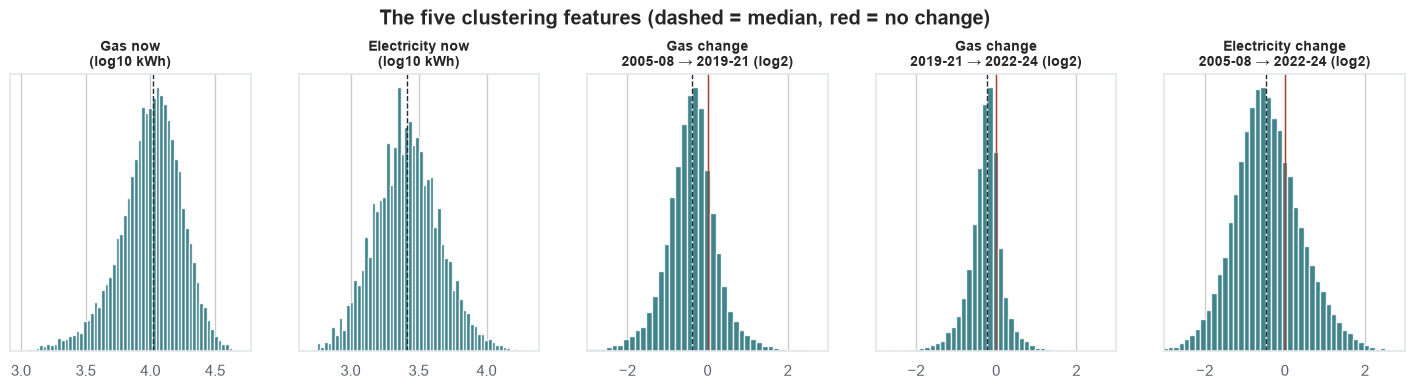

In [7]:
LABELS = {"log_gas_recent": "Gas now\n(log10 kWh)", "log_elec_recent": "Electricity now\n(log10 kWh)",
          "gas_change_long": "Gas change\n2005-08 → 2019-21 (log2)", "gas_change_crisis": "Gas change\n2019-21 → 2022-24 (log2)",
          "elec_change_long": "Electricity change\n2005-08 → 2022-24 (log2)"}

fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, col in zip(axes, FEATURES):
    ax.hist(df[col], bins=60, color=ACCENT, alpha=0.85)
    ax.axvline(df[col].median(), color=INK, linestyle="--", linewidth=1)
    if "change" in col:
        ax.axvline(0, color="#A63D2F", linewidth=1)
        ax.set_xlim(-3, 3)
    ax.set_title(LABELS[col], fontsize=10)
    ax.set_yticks([])
fig.suptitle("The five clustering features (dashed = median, red = no change)", y=1.06, fontweight="bold")
plt.show()

## 1.3 Scaling
The five features have **different units** (log kWh vs log ratios) and different spreads (std 0.24 for the levels, 0.5–0.85 for the changes). Without scaling, the electricity change, the widest feature, would dominate every distance. We standardise them with a `StandardScaler` (mean 0, std 1), so each feature has the same weight. The scaler is part of every pipeline below.

29,390 homes x 5 features; sample for slow methods: 6,000

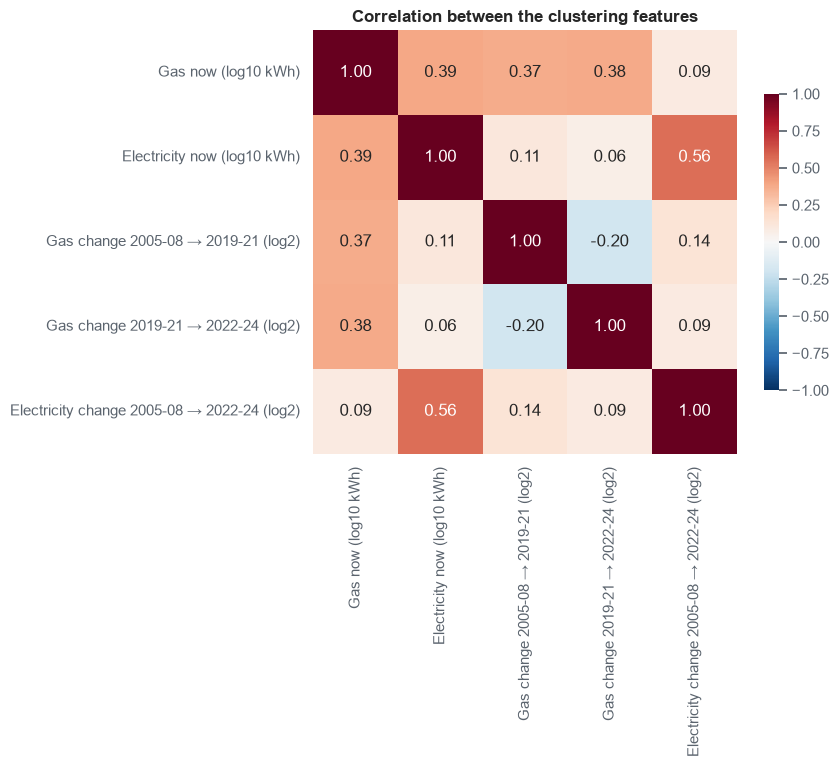

In [8]:
X = df[FEATURES].to_numpy()
scaler = StandardScaler().fit(X)
X_scaled = scaler.transform(X)

# A fixed random sample for the slow methods (silhouette, hierarchical, DBSCAN, t-SNE)
rng = np.random.default_rng(RANDOM_STATE)
SAMPLE = rng.choice(len(df), size=6000, replace=False)
X_sample = X_scaled[SAMPLE]
print(f"{len(df):,} homes x {len(FEATURES)} features; sample for slow methods: {len(SAMPLE):,}")

corr = df[FEATURES].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            xticklabels=[LABELS[c].replace("\n", " ") for c in FEATURES],
            yticklabels=[LABELS[c].replace("\n", " ") for c in FEATURES], cbar_kws={"shrink": 0.7})
plt.title("Correlation between the clustering features")
plt.show()

# 2. Step 1 – Dimensionality reduction

## 2.1 PCA: how many real dimensions?
PCA rotates the five scaled features into new axes (principal components) ordered by how much variance they explain. The **loadings** say what each axis means.

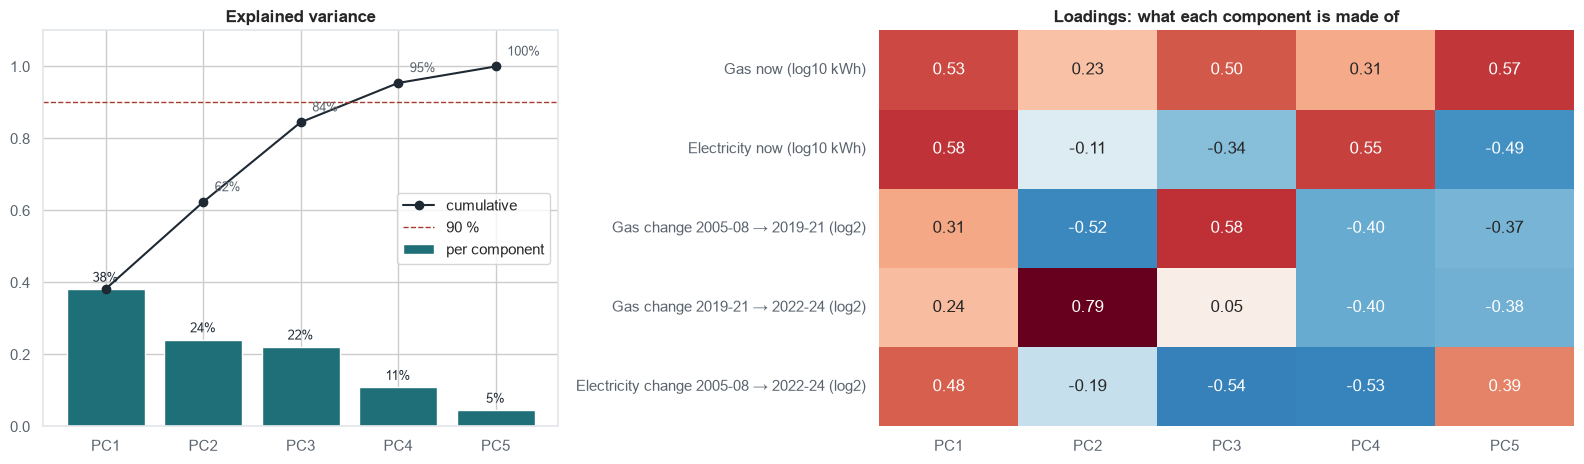

In [9]:
pca = PCA().fit(X_scaled)
explained = pca.explained_variance_ratio_
components = [f"PC{i + 1}" for i in range(len(explained))]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.35]})
axes[0].bar(components, explained, color=ACCENT, label="per component")
axes[0].plot(components, np.cumsum(explained), color=INK, marker="o", label="cumulative")
for i, (e, c) in enumerate(zip(explained, np.cumsum(explained))):
    axes[0].text(i, e + 0.02, f"{e:.0%}", ha="center", fontsize=9, color=INK)
    axes[0].text(i + 0.12, c + 0.03, f"{c:.0%}", ha="left", fontsize=9, color=MUTED_INK) if i else None
axes[0].axhline(0.9, color="#A63D2F", linestyle="--", linewidth=1, label="90 %")
axes[0].set_ylim(0, 1.1)
axes[0].set_title("Explained variance")
axes[0].legend(loc="center right")

loadings = pd.DataFrame(pca.components_.T, index=[LABELS[c].replace("\n", " ") for c in FEATURES], columns=components)
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.8, vmax=0.8, ax=axes[1], cbar=False)
axes[1].set_title("Loadings: what each component is made of")
plt.tight_layout()
save("02_pca_explained_variance.png")
plt.show()

**Reading the PCA.**
- **PC1 (38 %): "uses a lot and has not cut back".** Every feature loads positively: homes far to the right use more gas and electricity now **and** reduced less (or even increased). This is the main axis a retrofit programme cares about.
- **PC2 (24 %): "when did the home cut its gas?"** The 2022 crisis change (+0.79) is set against the long-term change (−0.52). Homes at one end saved early (2005–2021) and then held steady; homes at the other end saved little until the 2022 price shock.
- **PC3 (22 %): gas vs electricity.** Gas level and gas change (+) against electricity change (−): it separates homes whose gas and electricity trends went in different directions.
- 3 components explain **84 %**, 4 explain **95 %**. No feature is redundant: the five features really span **about four dimensions**. The data is not "secretly 1D", so a 2D picture will always hide something.

## 2.2 PCA, t-SNE and UMAP side by side
- **PCA** is linear: its axes have a meaning (the loadings above), and distances are faithful, but it can only show what fits on a flat plane.
- **t-SNE** and **UMAP** are non-linear: they keep **neighbours** together, so they show local structure well, but **the size of groups and the gaps between them do not mean anything**.

We compute PCA and UMAP for **all** homes (their coordinates go into the dataset), and t-SNE on the 6,000-home sample (t-SNE is slow and cannot place new points).

In [10]:
start = time.time()
pca_xy = PCA(n_components=2).fit_transform(X_scaled)
umap_model = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=RANDOM_STATE)
umap_xy = umap_model.fit_transform(X_scaled)
tsne_xy = TSNE(n_components=2, perplexity=40, random_state=RANDOM_STATE).fit_transform(X_sample)
print(f"PCA + UMAP ({len(df):,} homes) + t-SNE ({len(SAMPLE):,} homes): {time.time() - start:.0f} s")

/Users/luiswulf/Documents/IAAC/AI-Methods/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PCA + UMAP (29,390 homes) + t-SNE (6,000 homes): 29 s


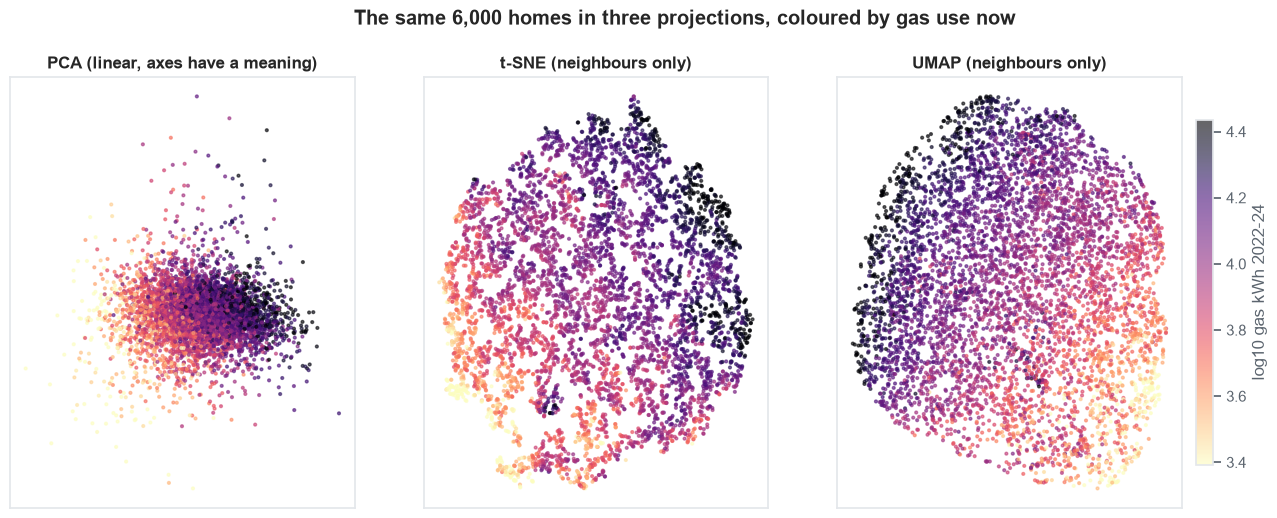

In [11]:
def three_maps(color_values, title, fig_name, cmap="viridis", label=None, categorical=False, palette=None):
    # PCA / t-SNE / UMAP next to each other, coloured by the same variable (sample only, for readability)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
    maps = [("PCA (linear, axes have a meaning)", pca_xy[SAMPLE]),
            ("t-SNE (neighbours only)", tsne_xy),
            ("UMAP (neighbours only)", umap_xy[SAMPLE])]
    values = np.asarray(color_values)[SAMPLE]
    for ax, (name, xy) in zip(axes, maps):
        if categorical:
            for cat in palette:
                m = values == cat
                ax.scatter(xy[m, 0], xy[m, 1], s=4, alpha=0.6, color=palette[cat], label=cat)
        else:
            sc = ax.scatter(xy[:, 0], xy[:, 1], c=values, s=4, alpha=0.6, cmap=cmap,
                            vmin=np.percentile(values, 2), vmax=np.percentile(values, 98))
        ax.set_title(name)
        ax.set_xticks([]); ax.set_yticks([])
    if categorical:
        axes[-1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), markerscale=4, frameon=False)
    else:
        fig.colorbar(sc, ax=axes, shrink=0.8, label=label, pad=0.01)
    fig.suptitle(title, fontweight="bold", y=1.0)
    save(fig_name)
    plt.show()


three_maps(df["log_gas_recent"], "The same 6,000 homes in three projections, coloured by gas use now",
           "03_projections_gas_level.png", cmap="magma_r", label="log10 gas kWh 2022-24")

**What the three maps show.**
- **No separate islands.** In all three projections the homes form one connected cloud with smooth colour gradients: gas use and its change vary **continuously**. We should expect clusters that *cut a continuum*, not clusters that discover separate populations (see the low silhouette below).
- **PCA** shows the gradient as a straight direction (low gas on the left, high gas on the right). **t-SNE and UMAP** pull neighbours together, so homes with similar trajectories form patches. The small, very dense t-SNE clumps are partly an artefact: NEED rounds readings to 100 kWh, so many homes share *exactly* the same values.
- As always with t-SNE and UMAP: the size of a patch and the gaps between patches do not mean anything.

# 3. Step 2 – Clustering

## 3.1 K-Means: choosing k
We fit K-Means for k = 2 … 10 and look at four internal metrics. **Inertia** always falls with more clusters (we look for an *elbow*); **silhouette** (higher is better, max 1) and **Calinski–Harabasz** (higher is better) reward compact and well-separated groups; **Davies–Bouldin** (lower is better) penalises overlapping groups. Silhouette is computed on the 6,000-home sample to keep it fast.

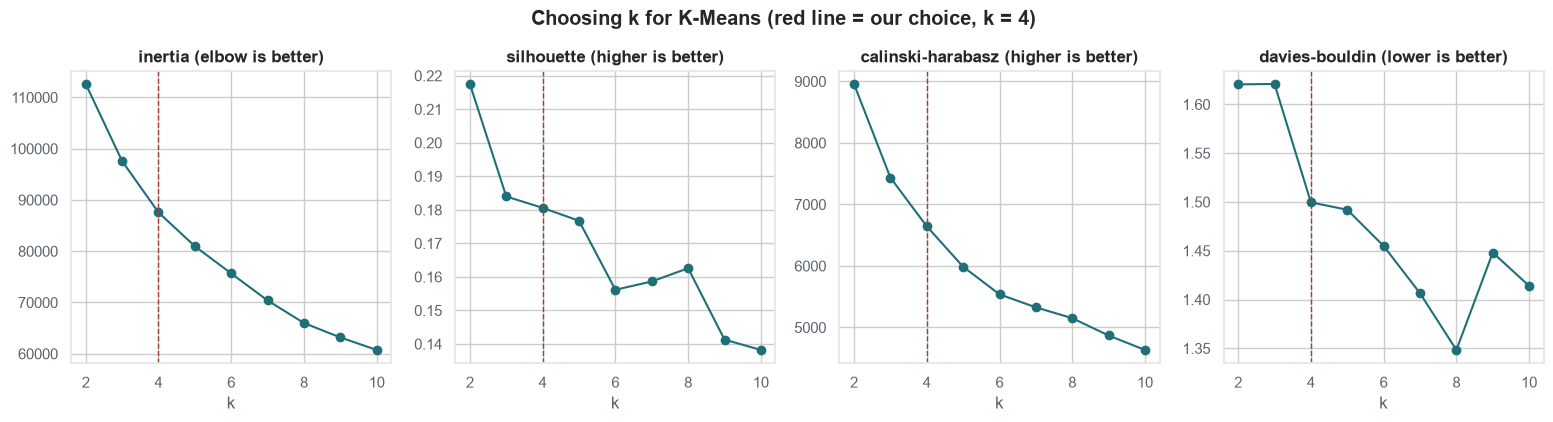

,inertia,silhouette,calinski_harabasz,davies_bouldin,smallest cluster
k,,,,,
2,112619.765,0.218,8958.623,1.620,13626
3,97569.651,0.184,7436.539,1.621,7092
4,87559.902,0.181,6644.024,1.500,4913
5,80966.378,0.177,5986.853,1.492,3481
6,75656.081,0.156,5538.007,1.455,2771
7,70387.729,0.159,5326.787,1.406,1323
8,65984.278,0.163,5150.444,1.348,1261
9,63184.508,0.141,4868.938,1.448,1116
10,60737.886,0.138,4633.634,1.414,1068


In [12]:
def scan_k(X, k_values, sample_idx):
    rows = []
    for k in k_values:
        model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
        labels = model.labels_
        rows.append({"k": k, "inertia": model.inertia_,
                     "silhouette": silhouette_score(X[sample_idx], labels[sample_idx]),
                     "calinski_harabasz": calinski_harabasz_score(X, labels),
                     "davies_bouldin": davies_bouldin_score(X, labels),
                     "smallest cluster": np.bincount(labels).min()})
    return pd.DataFrame(rows).set_index("k")


k_scan = scan_k(X_scaled, range(2, 11), SAMPLE)

fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
for ax, (col, better) in zip(axes, [("inertia", "elbow"), ("silhouette", "higher"),
                                    ("calinski_harabasz", "higher"), ("davies_bouldin", "lower")]):
    ax.plot(k_scan.index, k_scan[col], marker="o", color=ACCENT)
    ax.axvline(4, color="#A63D2F", linestyle="--", linewidth=1)
    ax.set_title(f"{col.replace('_', '-')} ({better} is better)")
    ax.set_xlabel("k")
fig.suptitle("Choosing k for K-Means (red line = our choice, k = 4)", fontweight="bold", y=1.04)
save("04_choice_of_k.png")
plt.show()
k_scan.round(3)

**Reading the scan.** No k stands out clearly, a common situation with real data. All silhouettes are below 0.25 (weak structure, as the maps suggested). The highest is at **k = 2**, but that split only says "high users vs low users", which a single threshold on the gas reading could give us. Inertia has no sharp elbow.

We choose **k = 4** because:
1. Davies–Bouldin improves clearly from k = 3 (1.62) to k = 4 (1.50) while the silhouette stays about the same (0.184 → 0.181).
2. The smallest group still contains **17 %** of the homes: every group is large enough to act on.
3. The four groups are **interpretable and actionable** (section 5); with k = 5–6 the extra groups split existing ones by level only.
4. The result is **stable** (section 4).

In [13]:
N_CLUSTERS = 4
final_model = make_pipeline(StandardScaler(), KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE))
df["cluster"] = final_model.fit_predict(df[FEATURES])
print(df["cluster"].value_counts().sort_index())

# Silhouette per home (sample): which clusters are clear, which are fuzzy?
sil = silhouette_samples(X_sample, df["cluster"].to_numpy()[SAMPLE])
print("\nMean silhouette per cluster:")
print(pd.Series(sil).groupby(df["cluster"].to_numpy()[SAMPLE]).mean().round(3))

cluster
0     8787
1     4966
2     4913
3    10724
Name: count, dtype: int64

Mean silhouette per cluster:
0    0.173
1    0.099
2    0.088
3    0.263
dtype: float64


## 3.2 Hierarchical clustering (Ward)
Hierarchical clustering merges the two most similar groups step by step. The **dendrogram** shows the whole merge history: long vertical lines mean a merge of two groups that are far apart, which is a natural place to cut. We use Ward linkage (it merges the groups whose union increases the variance least, the same criterion as K-Means) on the 6,000-home sample, and show the top of the tree.

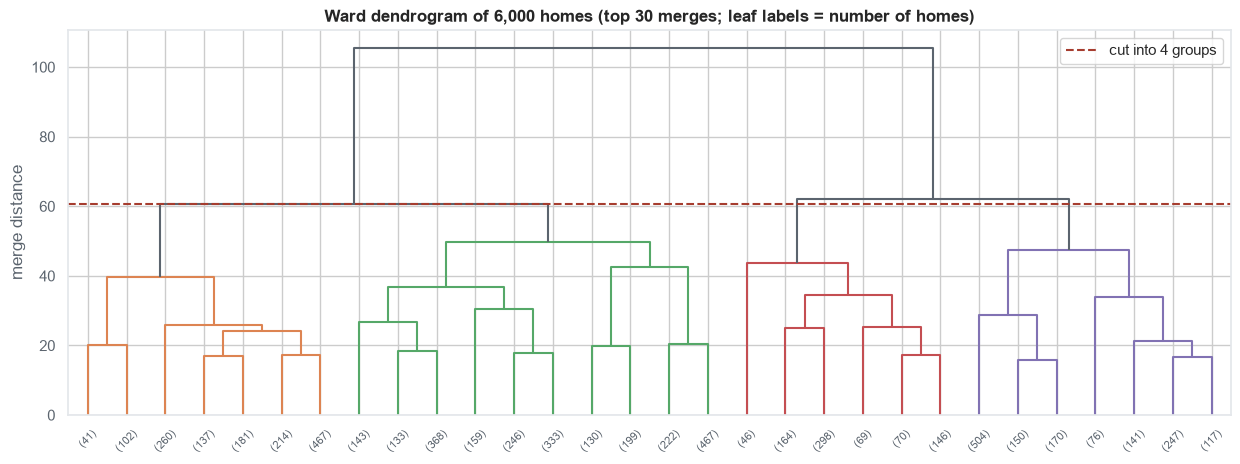

ARI K-Means vs Ward (k = 4): 0.27


Ward,0,1,2,3
K-Means,,,,
0,1507,0,10,288
1,189,545,231,31
2,256,106,527,82
3,448,754,25,1001


In [14]:
tree = linkage(X_sample, method="ward")

fig, ax = plt.subplots(figsize=(15, 5))
dendrogram(tree, truncate_mode="lastp", p=30, color_threshold=tree[-(N_CLUSTERS - 1), 2],
           above_threshold_color=MUTED_INK, show_leaf_counts=True, leaf_font_size=8, ax=ax)
ax.axhline(tree[-(N_CLUSTERS - 1), 2] * 0.98 + tree[-N_CLUSTERS, 2] * 0.02, color="#A63D2F", linestyle="--",
           label=f"cut into {N_CLUSTERS} groups")
ax.set_title("Ward dendrogram of 6,000 homes (top 30 merges; leaf labels = number of homes)")
ax.set_ylabel("merge distance")
ax.legend()
save("05_dendrogram.png")
plt.show()

ward_labels = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage="ward").fit_predict(X_sample)
kmeans_sample = df["cluster"].to_numpy()[SAMPLE]
print(f"ARI K-Means vs Ward (k = {N_CLUSTERS}): {adjusted_rand_score(kmeans_sample, ward_labels):.2f}")
pd.crosstab(pd.Series(kmeans_sample, name="K-Means"), pd.Series(ward_labels, name="Ward"))

**Reading the dendrogram and the comparison.** The tree has no long vertical lines at the top: the last merges happen at similar heights, which is again the signature of a **continuum** (in clearly separated data the last few merges stand out). Cutting it into 4 gives groups that **only partly agree** with K-Means (ARI = 0.27). The cross-table shows the main agreement: K-Means group 0 is almost entirely Ward group 0, and the two low-use K-Means groups share Ward groups 1 and 2. The two algorithms draw the borders inside the cloud in different places, which is expected when there are no natural gaps. We keep K-Means as the final model: its groups are balanced, it can `.predict()` new homes and it is stable (section 4).

## 3.3 DBSCAN: density and outliers
DBSCAN does not take a number of clusters: it grows clusters from dense regions and labels isolated points as **noise (−1)**. We pick `eps` with the **k-distance plot**: the sorted distance of every home to its 10th nearest neighbour. The "knee", where the curve shoots up, separates dense regions from isolated points.

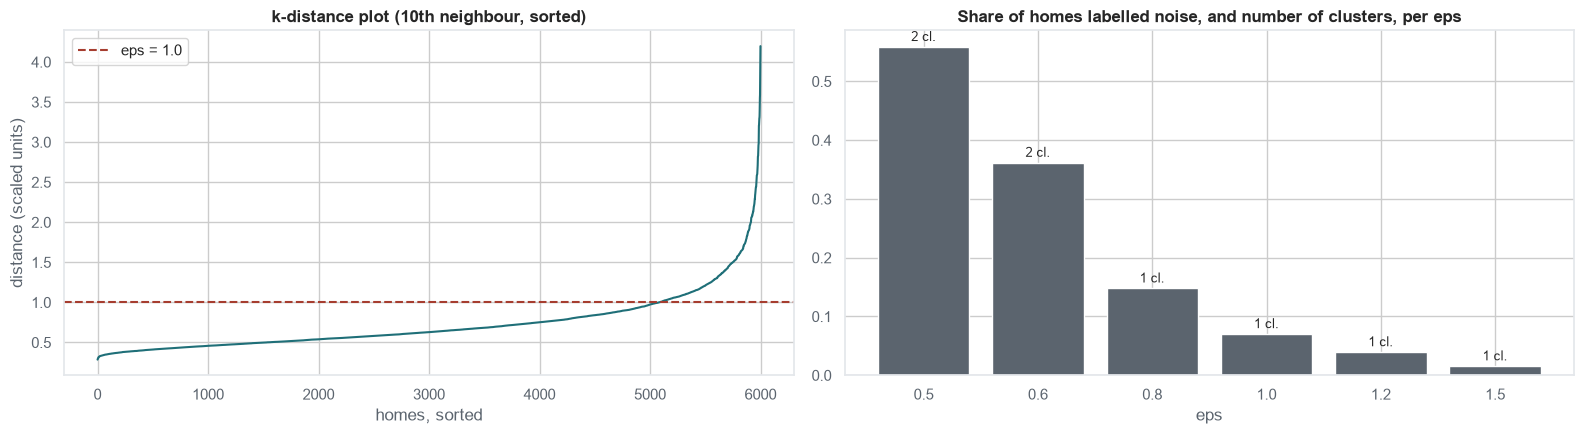

,eps,clusters,noise share
0,0.5,2,0.559
1,0.6,2,0.362
2,0.8,1,0.148
3,1.0,1,0.070
4,1.2,1,0.039
5,1.5,1,0.015


In [15]:
MIN_SAMPLES = 10
distances, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES + 1).fit(X_sample).kneighbors(X_sample)
k_dist = np.sort(distances[:, MIN_SAMPLES])
EPS = 1.0

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(k_dist, color=ACCENT)
axes[0].axhline(EPS, color="#A63D2F", linestyle="--", label=f"eps = {EPS}")
axes[0].set_title(f"k-distance plot ({MIN_SAMPLES}th neighbour, sorted)")
axes[0].set_xlabel("homes, sorted")
axes[0].set_ylabel("distance (scaled units)")
axes[0].legend()

rows = []
for eps in [0.5, 0.6, 0.8, 1.0, 1.2, 1.5]:
    labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_sample)
    rows.append({"eps": eps, "clusters": len(set(labels)) - (-1 in labels), "noise share": (labels == -1).mean()})
eps_scan = pd.DataFrame(rows)
axes[1].bar(eps_scan["eps"].astype(str), eps_scan["noise share"], color=MUTED_INK)
for i, r in eps_scan.iterrows():
    axes[1].text(i, r["noise share"] + 0.01, f"{int(r['clusters'])} cl.", ha="center", fontsize=9)
axes[1].set_title("Share of homes labelled noise, and number of clusters, per eps")
axes[1].set_xlabel("eps")
plt.tight_layout()
save("06_dbscan_k_distance.png")
plt.show()
eps_scan.round(3)

In [16]:
dbscan_labels = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X_sample)
is_noise = dbscan_labels == -1
print(f"DBSCAN (eps={EPS}): {len(set(dbscan_labels)) - is_noise.any()} cluster(s), {is_noise.sum()} noise homes ({is_noise.mean():.1%})")

sample_df = df.iloc[SAMPLE]
compare = pd.DataFrame({"dense core": sample_df.loc[~is_noise, FEATURES].median(),
                        "DBSCAN noise": sample_df.loc[is_noise, FEATURES].median()})
compare["noise: share with |change| > 1"] = [np.nan, np.nan] + [
    (sample_df.loc[is_noise, c].abs() > 1).mean() for c in FEATURES[2:]]
compare.round(2)

DBSCAN (eps=1.0): 1 cluster(s), 421 noise homes (7.0%)


,dense core,DBSCAN noise,noise: share with |change| > 1
log_gas_recent,4.03,3.78,NaN
log_elec_recent,3.41,3.33,NaN
gas_change_long,-0.37,-0.49,0.58
gas_change_crisis,-0.23,-0.30,0.44
elec_change_long,-0.48,-0.31,0.48


**Reading DBSCAN.** DBSCAN finds **one big dense cluster** for every reasonable `eps`. With small `eps` (0.5–0.6) half of the homes are labelled noise and only two tiny extra clusters appear; with `eps = 1.0` (the knee of the k-distance plot) there is one cluster and **7 % noise**. So there are **no density-separated groups** of households, which confirms the continuum seen above.

DBSCAN is still useful here, as an **outlier detector**: the noise homes use less gas and, above all, **58 % of them doubled or halved their gas** between two windows. These are homes whose occupancy or use changed (empty for a period, extended, converted) or with doubtful readings. We publish this flag (`dbscan_outlier`) so that users can exclude them.

**Which algorithm fits this data?** Our data is one continuous cloud. **DBSCAN** (density) correctly says "one population + outliers" but cannot segment it. **K-Means** and **Ward** both cut the cloud into compact pieces, in somewhat different places. For a programme that must split *every* home into an action group, a cut of a continuum is exactly what we need, provided it is stable and interpretable. That is why the final model is K-Means, with DBSCAN kept as an outlier flag.

# 4. Stability

Are the four groups a property of the data or an accident of one run? We check two things with the adjusted Rand index (ARI; 1 = identical grouping, 0 = random):
1. **Different seeds**: refit with `random_state` 0 … 9 on all homes.
2. **Different data**: refit on 10 random 80 % subsamples and assign *all* homes with `.predict()`.

In [17]:
reference = df["cluster"].to_numpy()
seed_ari = [adjusted_rand_score(reference, make_pipeline(StandardScaler(), KMeans(N_CLUSTERS, n_init=10, random_state=s))
                                .fit_predict(df[FEATURES])) for s in range(10)]
sub_ari = []
for s in range(10):
    idx = np.random.default_rng(s).choice(len(df), size=int(0.8 * len(df)), replace=False)
    model = make_pipeline(StandardScaler(), KMeans(N_CLUSTERS, n_init=10, random_state=RANDOM_STATE)).fit(df.iloc[idx][FEATURES])
    sub_ari.append(adjusted_rand_score(reference, model.predict(df[FEATURES])))

stability = pd.DataFrame({"10 seeds": seed_ari, "10 subsamples (80 %)": sub_ari})
print(f"K-Means vs Ward on the sample: ARI = {adjusted_rand_score(kmeans_sample, ward_labels):.2f}")
stability.describe().loc[["mean", "min", "max"]].round(3)

K-Means vs Ward on the sample: ARI = 0.27


,10 seeds,10 subsamples (80 %)
mean,0.984,0.963
min,0.982,0.937
max,0.985,0.987


**Reading the stability check.** Changing the seed gives almost the same groups (ARI ≈ **0.98**), and fitting on 80 % of the homes still gives ARI ≥ **0.94**. The four groups are therefore a **reproducible** way of cutting the data, even though they are not separated by gaps. The disagreement with Ward (0.27) reminds us that they are *one* reasonable cut, not the only one.

# 5. Step 3 – Application: interpreting and naming the groups

## 5.1 Profiles: what do the groups look like on the clustering features?

In [18]:
profile = df.groupby("cluster").agg(
    homes=("cluster", "size"),
    gas_now_kwh=("gas_recent_kwh", "median"),
    elec_now_kwh=("elec_recent_kwh", "median"),
    gas_2005_08_kwh=("gas_early_kwh", "median"),
    gas_change_long=("gas_change_long", "median"),
    gas_change_crisis=("gas_change_crisis", "median"),
    elec_change_long=("elec_change_long", "median"),
)
profile.insert(1, "share", (profile["homes"] / len(df)).round(3))
profile["gas_long_%"] = ((2 ** profile["gas_change_long"] - 1) * 100).round(0)
profile["gas_crisis_%"] = ((2 ** profile["gas_change_crisis"] - 1) * 100).round(0)
profile["elec_long_%"] = ((2 ** profile["elec_change_long"] - 1) * 100).round(0)
profile.round(2)

,homes,share,gas_now_kwh,elec_now_kwh,gas_2005_08_kwh,gas_change_long,gas_change_crisis,elec_change_long,gas_long_%,gas_crisis_%,elec_long_%
cluster,,,,,,,,,,,
0,8787,0.30,12900.00,4400.00,17950.00,-0.24,-0.22,0.31,-15.0,-14.0,24.0
1,4966,0.17,5466.67,1733.33,13512.50,-0.52,-0.74,-0.79,-30.0,-40.0,-42.0
2,4913,0.17,7366.67,2066.67,15600.00,-1.10,-0.02,-0.55,-53.0,-2.0,-32.0
3,10724,0.36,12700.00,2266.67,17733.33,-0.25,-0.20,-0.81,-16.0,-13.0,-43.0


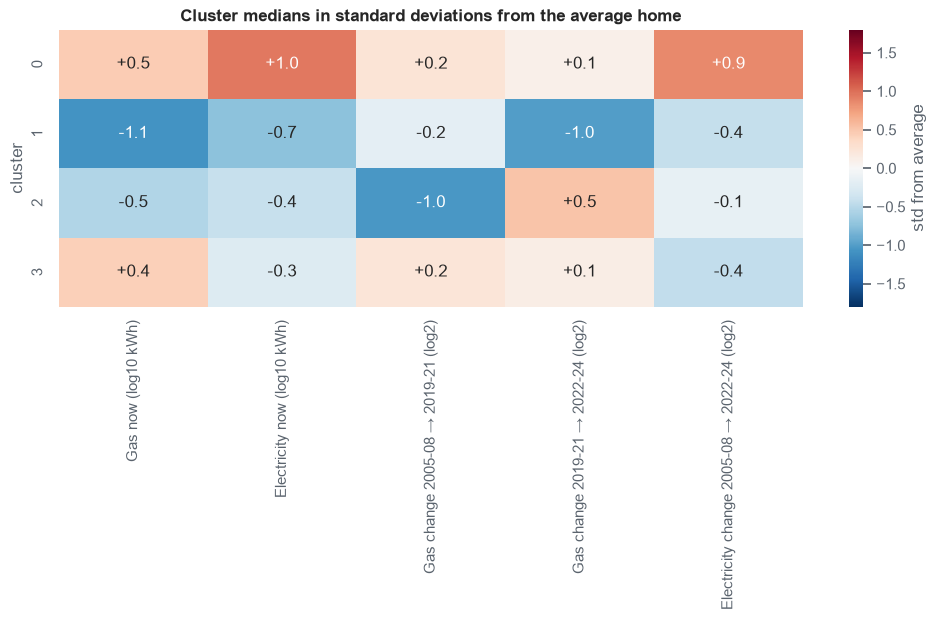

In [19]:
# Heatmap of the cluster centres in standard deviations (how far each group is from the average home)
z = pd.DataFrame(scaler.transform(df.groupby("cluster")[FEATURES].median().to_numpy()), columns=FEATURES)
z.columns = [LABELS[c].replace("\n", " ") for c in FEATURES]
plt.figure(figsize=(12, 3.6))
sns.heatmap(z, annot=True, fmt="+.1f", cmap="RdBu_r", center=0, vmin=-1.8, vmax=1.8, cbar_kws={"label": "std from average"})
plt.title("Cluster medians in standard deviations from the average home")
plt.ylabel("cluster")
plt.show()

**Reading the profiles** (cluster numbers as K-Means returned them):

| Cluster | Homes | Gas now | Electricity now | Gas 2005–08 → 2019–21 | Gas in crisis | Electricity since 2005 |
|---|---|---|---|---|---|---|
| 0 | 8,787 (30 %) | **12,900** kWh | **4,400** kWh (highest) | −15 % | −14 % | **+24 %** (only group that grew) |
| 1 | 4,966 (17 %) | **5,470** kWh (lowest) | 1,730 kWh | −30 % | **−40 %** | −42 % |
| 2 | 4,913 (17 %) | 7,370 kWh | 2,070 kWh | **−53 %** | −2 % | −32 % |
| 3 | 10,724 (36 %) | **12,700** kWh | 2,270 kWh | −16 % | −13 % | −43 % |

(For reference: the median gas-heated home uses about 10,500 kWh of gas per year now.)

In [20]:
# Our names (justified in section 5.4). The order sets the colours: red = retrofit priority.
CLUSTER_NAMES = {
    3: "high gas, slow reducers",
    0: "high users, rising electricity",
    1: "low users, deep crisis cuts",
    2: "early reducers, now low gas",
}
CLUSTER_COLORS = dict(zip(CLUSTER_NAMES.values(), ["#A63D2F", "#C98A3B", "#5A4E8C", "#1F6F78"]))
ORDER = list(CLUSTER_NAMES.values())
df["cluster_name"] = df["cluster"].map(CLUSTER_NAMES)
df["cluster_name"].value_counts()[ORDER]

SHARE = df["cluster_name"].value_counts(normalize=True)
CHANGE = {col: (2 ** df.groupby("cluster_name")[col].median() - 1) * 100
          for col in ["gas_change_long", "gas_change_crisis", "elec_change_long"]}
ACTIONS = {
    "high gas, slow reducers": "Retrofit priority:\ninsulation + EPC survey",
    "high users, rising electricity": "Large-home retrofit\n+ electricity advice / PV",
    "low users, deep crisis cuts": "Fuel-poverty check:\npossibly cold, not efficient",
    "early reducers, now low gas": "Low priority:\nmonitor",
}

## 5.2 Twenty years of gas and electricity, per group
The clustering only saw three windows per fuel. Here we plot the **full yearly series** (median of the valid readings per year) to check that the groups really follow different trajectories.

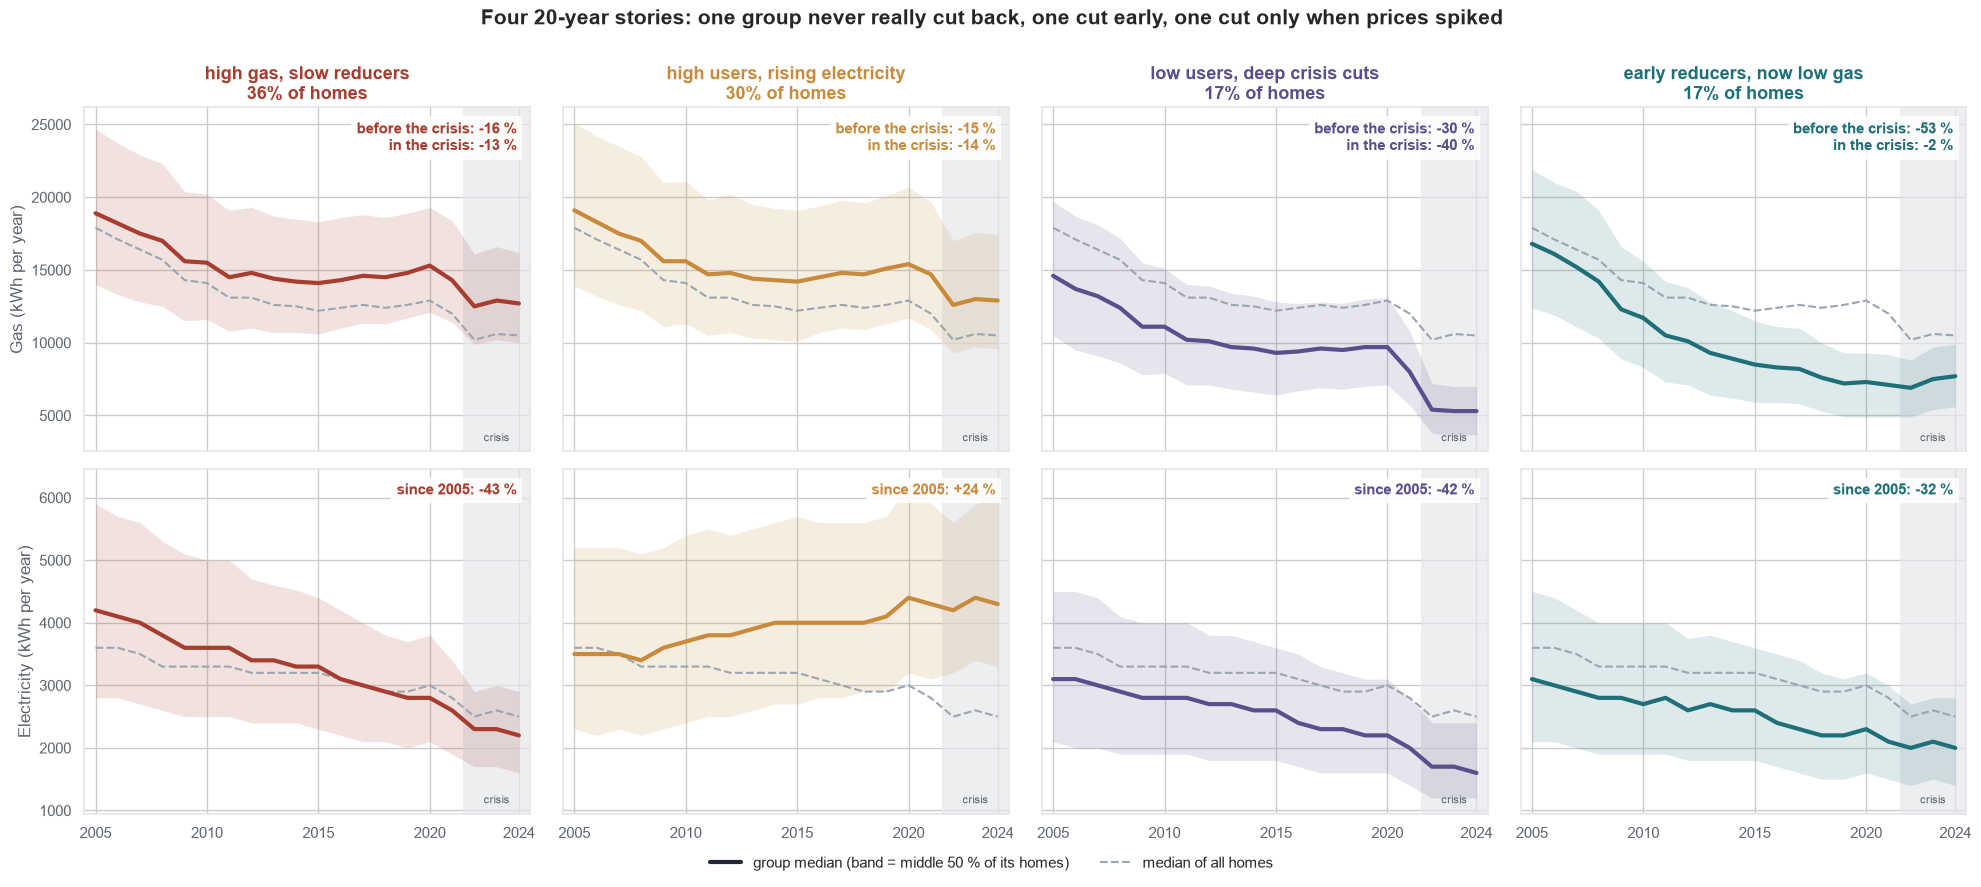

In [21]:
from matplotlib.lines import Line2D

gas_c = gas.loc[gas_homes.index[complete]].reset_index(drop=True)
elec_c = elec.loc[gas_homes.index[complete]].reset_index(drop=True)

fig, axes = plt.subplots(2, 4, figsize=(20, 8.5), sharex=True, sharey="row")
for row, (table, fuel) in enumerate([(gas_c, "Gas"), (elec_c, "Electricity")]):
    everyone = table.median()
    for ax, name in zip(axes[row], ORDER):
        color = CLUSTER_COLORS[name]
        part = table[df["cluster_name"] == name]
        ax.axvspan(2021.5, 2024.5, color=GRID, alpha=0.7, linewidth=0)
        ax.plot(YEARS, everyone, color="#9AA5B1", linewidth=1.5, linestyle="--")
        ax.fill_between(YEARS, part.quantile(0.25), part.quantile(0.75), color=color, alpha=0.15, linewidth=0)
        ax.plot(YEARS, part.median(), color=color, linewidth=3)
        if row == 0:
            ax.set_title(f"{name}\n{SHARE[name]:.0%} of homes", color=color, fontsize=13)
            note = (f"before the crisis: {CHANGE['gas_change_long'][name]:+.0f} %\n"
                    f"in the crisis: {CHANGE['gas_change_crisis'][name]:+.0f} %")
        else:
            note = f"since 2005: {CHANGE['elec_change_long'][name]:+.0f} %"
        ax.text(0.97, 0.96, note, transform=ax.transAxes, ha="right", va="top", fontsize=11,
                fontweight="bold", color=color, bbox=dict(facecolor="white", edgecolor="none", alpha=0.85))
        ax.text(2023, 0.03, "crisis", transform=ax.get_xaxis_transform(), ha="center", fontsize=8, color=MUTED_INK)
        ax.set_xticks([2005, 2010, 2015, 2020, 2024])
        ax.set_xlim(2004.5, 2024.5)
    axes[row, 0].set_ylabel(f"{fuel} (kWh per year)")
handles = [Line2D([], [], color=INK, linewidth=3, label="group median (band = middle 50 % of its homes)"),
           Line2D([], [], color="#9AA5B1", linewidth=1.5, linestyle="--", label="median of all homes")]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Four 20-year stories: one group never really cut back, one cut early, one cut only when prices spiked",
             fontweight="bold", fontsize=15, y=1.0)
plt.tight_layout()
save("09_trajectories_per_cluster.png")
plt.show()

## 5.3 Cross-tabulation with variables we did **not** cluster on
If the groups were random, every group would have the same mix of dwelling types, sizes, EPC bands and deprivation levels. Each heatmap row sums to 100 %, the last row ("all homes") is the reference.

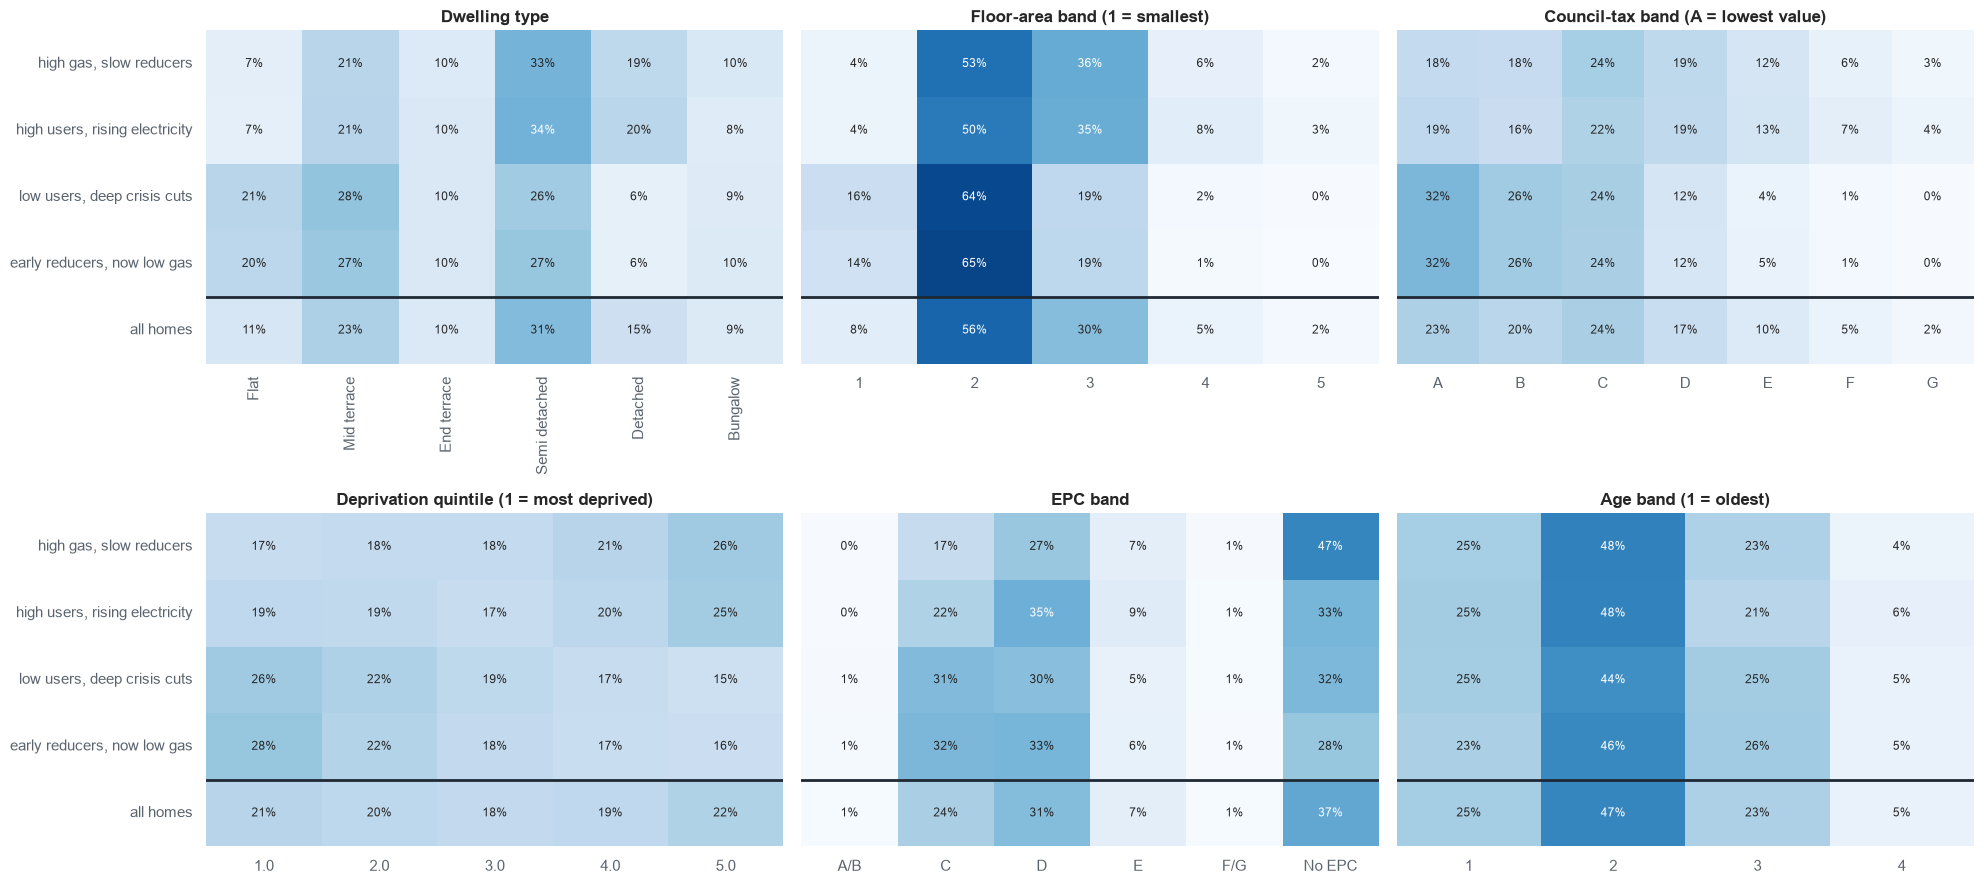

In [22]:
def share_table(col, order=None):
    table = pd.crosstab(df["cluster_name"], df[col], normalize="index").reindex(ORDER)
    table.loc["all homes"] = df[col].value_counts(normalize=True)
    return table[order] if order else table


panels = [
    ("PROP_TYPE", "Dwelling type", ["Flat", "Mid terrace", "End terrace", "Semi detached", "Detached", "Bungalow"]),
    ("FLOOR_AREA_BAND", "Floor-area band (1 = smallest)", [1, 2, 3, 4, 5]),
    ("COUNCIL_TAX_BAND", "Council-tax band (A = lowest value)", list("ABCDEFG")),
    ("imd_band", "Deprivation quintile (1 = most deprived)", [1.0, 2.0, 3.0, 4.0, 5.0]),
    ("EPC", "EPC band", ["A/B", "C", "D", "E", "F/G", "No EPC"]),
    ("PROP_AGE_BAND", "Age band (1 = oldest)", [1, 2, 3, 4]),
]
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for ax, (col, title, order) in zip(axes.ravel(), panels):
    table = share_table(col, order)
    sns.heatmap(table, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax, vmin=0, vmax=0.7,
                annot_kws={"fontsize": 8.5})
    ax.axhline(len(ORDER), color=INK, linewidth=2)
    ax.set_title(title)
    ax.set_xlabel(""); ax.set_ylabel("")
    if ax not in axes[:, 0]:
        ax.set_yticklabels([])
plt.tight_layout()
plt.show()

**The cross-tabs in one picture.** Each cell is the difference between a group and the average home, in percentage points (the share inside the group is in brackets). Red = more common in this group, blue = less common.

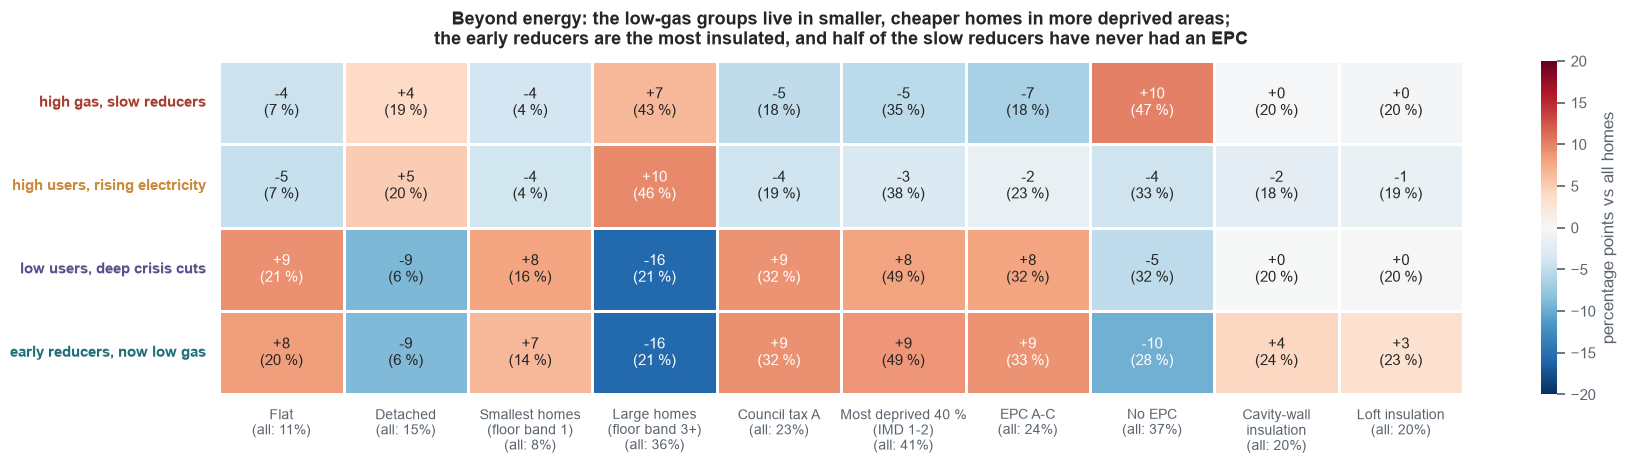

In [23]:
indicators = pd.DataFrame({
    "Flat": df["PROP_TYPE"] == "Flat",
    "Detached": df["PROP_TYPE"] == "Detached",
    "Smallest homes\n(floor band 1)": df["FLOOR_AREA_BAND"] == 1,
    "Large homes\n(floor band 3+)": df["FLOOR_AREA_BAND"] >= 3,
    "Council tax A": df["COUNCIL_TAX_BAND"] == "A",
    "Most deprived 40 %\n(IMD 1-2)": df["imd_band"] <= 2,
    "EPC A-C": df["EPC"].isin(["A/B", "C"]),
    "No EPC": df["EPC"] == "No EPC",
    "Cavity-wall\ninsulation": df["CWI_FLAG"] == 1,
    "Loft insulation": df["LI_FLAG"] == 1,
}).astype(float)
in_group = indicators.groupby(df["cluster_name"]).mean().reindex(ORDER) * 100
difference = in_group - indicators.mean() * 100
labels = difference.map(lambda v: f"{round(v) + 0:+d}") + in_group.map(lambda v: f"\n({v:.0f} %)")

fig, ax = plt.subplots(figsize=(18, 4.8))
sns.heatmap(difference, annot=labels, fmt="", cmap="RdBu_r", center=0, vmin=-20, vmax=20, ax=ax,
            linewidths=2, linecolor="white", annot_kws={"fontsize": 11},
            cbar_kws={"label": "percentage points vs all homes"})
ax.set_xticklabels([f"{c}\n(all: {indicators[c].mean():.0%})" for c in difference.columns], rotation=0, fontsize=10)
ax.set_ylabel(""); ax.set_xlabel("")
for tick in ax.get_yticklabels():
    tick.set_color(CLUSTER_COLORS[tick.get_text()])
    tick.set_fontweight("bold")
ax.set_title("Beyond energy: the low-gas groups live in smaller, cheaper homes in more deprived areas;\n"
             "the early reducers are the most insulated, and half of the slow reducers have never had an EPC",
             fontsize=13, pad=12)
plt.tight_layout()
save("10_crosstabs_building_characteristics.png")
plt.show()

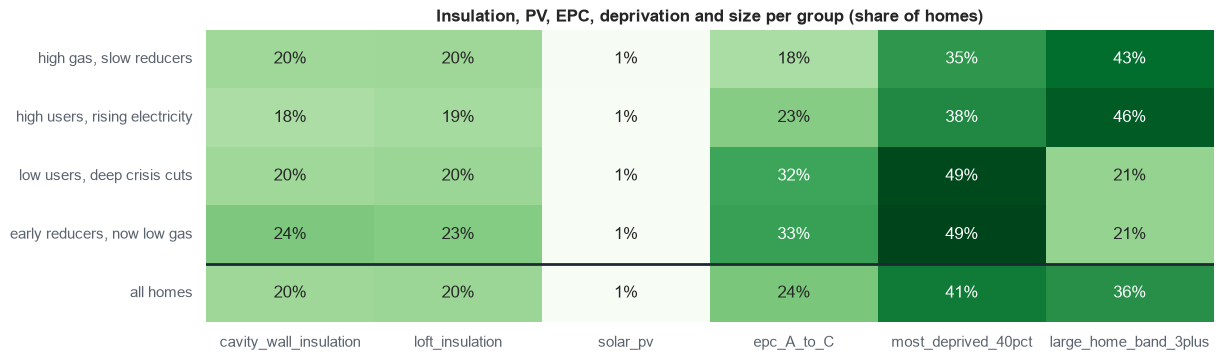

,cavity_wall_insulation,loft_insulation,solar_pv,epc_A_to_C,most_deprived_40pct,large_home_band_3plus
cluster_name,,,,,,
"high gas, slow reducers",0.195,0.196,0.014,0.178,0.351,0.431
"high users, rising electricity",0.177,0.186,0.011,0.228,0.378,0.460
"low users, deep crisis cuts",0.196,0.200,0.013,0.323,0.486,0.208
"early reducers, now low gas",0.240,0.231,0.012,0.333,0.494,0.208
all homes,0.197,0.200,0.013,0.243,0.406,0.365


In [24]:
# Retrofit measures and outcome indicators: share of homes per group
measures = df.groupby("cluster_name").agg(
    cavity_wall_insulation=("CWI_FLAG", "mean"),
    loft_insulation=("LI_FLAG", "mean"),
    solar_pv=("PV_FLAG", "mean"),
    epc_A_to_C=("EPC", lambda s: s.isin(["A/B", "C"]).mean()),
    most_deprived_40pct=("imd_band", lambda s: (s <= 2).mean()),
    large_home_band_3plus=("FLOOR_AREA_BAND", lambda s: (s >= 3).mean()),
).reindex(ORDER)
measures.loc["all homes"] = [df["CWI_FLAG"].mean(), df["LI_FLAG"].mean(), df["PV_FLAG"].mean(),
                             df["EPC"].isin(["A/B", "C"]).mean(), (df["imd_band"] <= 2).mean(),
                             (df["FLOOR_AREA_BAND"] >= 3).mean()]

fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(measures, annot=True, fmt=".0%", cmap="Greens", cbar=False, ax=ax)
ax.axhline(len(ORDER), color=INK, linewidth=2)
ax.set_title("Insulation, PV, EPC, deprivation and size per group (share of homes)")
ax.set_ylabel("")
plt.show()
measures.round(3)

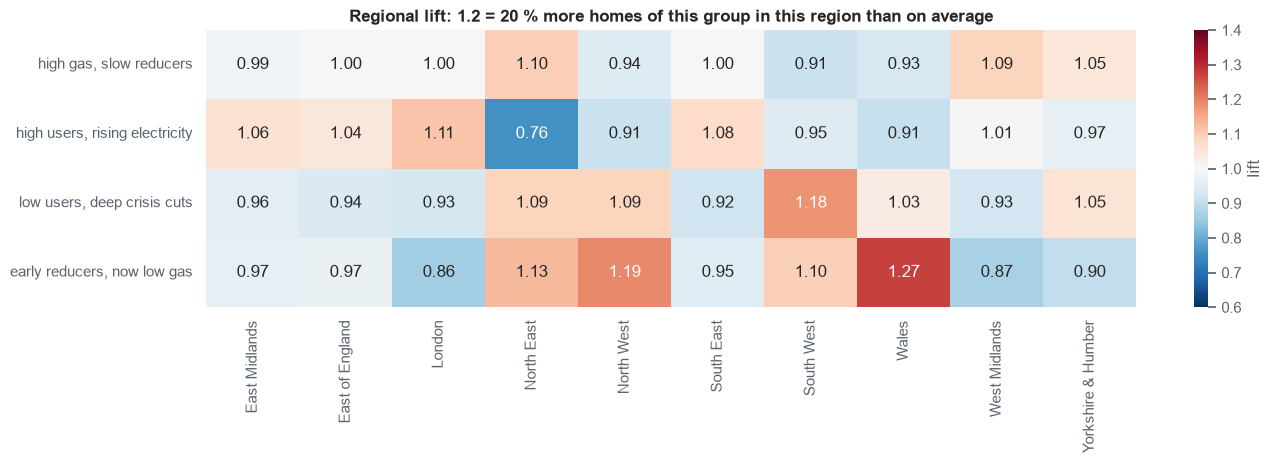

In [25]:
# Region: where are the groups over- or under-represented? (share in group / share in all homes)
region_lift = (pd.crosstab(df["cluster_name"], df["region_name"], normalize="index").reindex(ORDER)
               / df["region_name"].value_counts(normalize=True))
plt.figure(figsize=(15, 3.6))
sns.heatmap(region_lift, annot=True, fmt=".2f", cmap="RdBu_r", center=1, vmin=0.6, vmax=1.4, cbar_kws={"label": "lift"})
plt.title("Regional lift: 1.2 = 20 % more homes of this group in this region than on average")
plt.ylabel(""); plt.xlabel("")
plt.show()

## 5.4 Naming the groups

| # | Name | Size | Defining features | Justification (profiles + cross-tabs) | Suggested action |
|---|---|---|---|---|---|
| 3 | **high gas, slow reducers** | 10,724 (36 %) | 12,700 kWh gas, only −16 % since 2005 and −13 % in the crisis | Larger homes (43 % floor band ≥ 3), more detached and semi-detached, less deprived. **Lowest share of EPC A–C (17 %) and highest share without any EPC (47 %)**: the stock nobody has assessed or improved | **Retrofit priority**: insulation and heating upgrades, start with an EPC survey |
| 0 | **high users, rising electricity** | 8,787 (30 %) | 12,900 kWh gas **and** the highest electricity (4,400 kWh, **+24 %** since 2005) | Same building mix as group 3 (large, detached/semi, council tax D–G, least deprived, more in London and the South East). Electricity grew while everyone else's fell: more occupants, home working, electric vehicles or heat pumps added to the gas boiler | Large-home retrofit **plus** electricity advice / PV; check for EV or heat-pump hybrids |
| 1 | **low users, deep crisis cuts** | 4,966 (17 %) | The lowest gas (5,470 kWh) and electricity (1,730 kWh); gas fell **−40 % in 2022** | Small homes (80 % floor band ≤ 2), many flats and terraces, council tax A–B, **most deprived (48 % in the 2 most deprived quintiles)**. Gas dropped suddenly in 2022 after a stable decade (trajectory plot): a classic sign of **rationing heat** under high prices, not of a retrofit | **Fuel-poverty check**: these homes may be cold rather than efficient |
| 2 | **early reducers, now low gas** | 4,913 (17 %) | Gas halved **before** 2021 (−53 %), almost no change in the crisis (−2 %) | Small, often flats and terraces, deprived areas like group 1, but the **highest share of cavity-wall and loft insulation (24 % / 23 %) and of EPC A–C (33 %)**; over-represented in Wales and the North West, where large insulation schemes ran. The steady decline 2005–2019 matches retrofit, not rationing | Lowest priority for fabric retrofit; monitor |

**What did *not* differ:** the age band of the dwelling is nearly identical in all groups, and solar PV is rare everywhere (~1 %). The groups are about **size, wealth and history of intervention**, not about construction period.

⚠️ The names describe **typical** members. With a silhouette of ~0.18, many homes sit near a border; the `cluster_name` of an individual home is a starting point for a survey, not a verdict.

## 5.5 The named groups on the maps

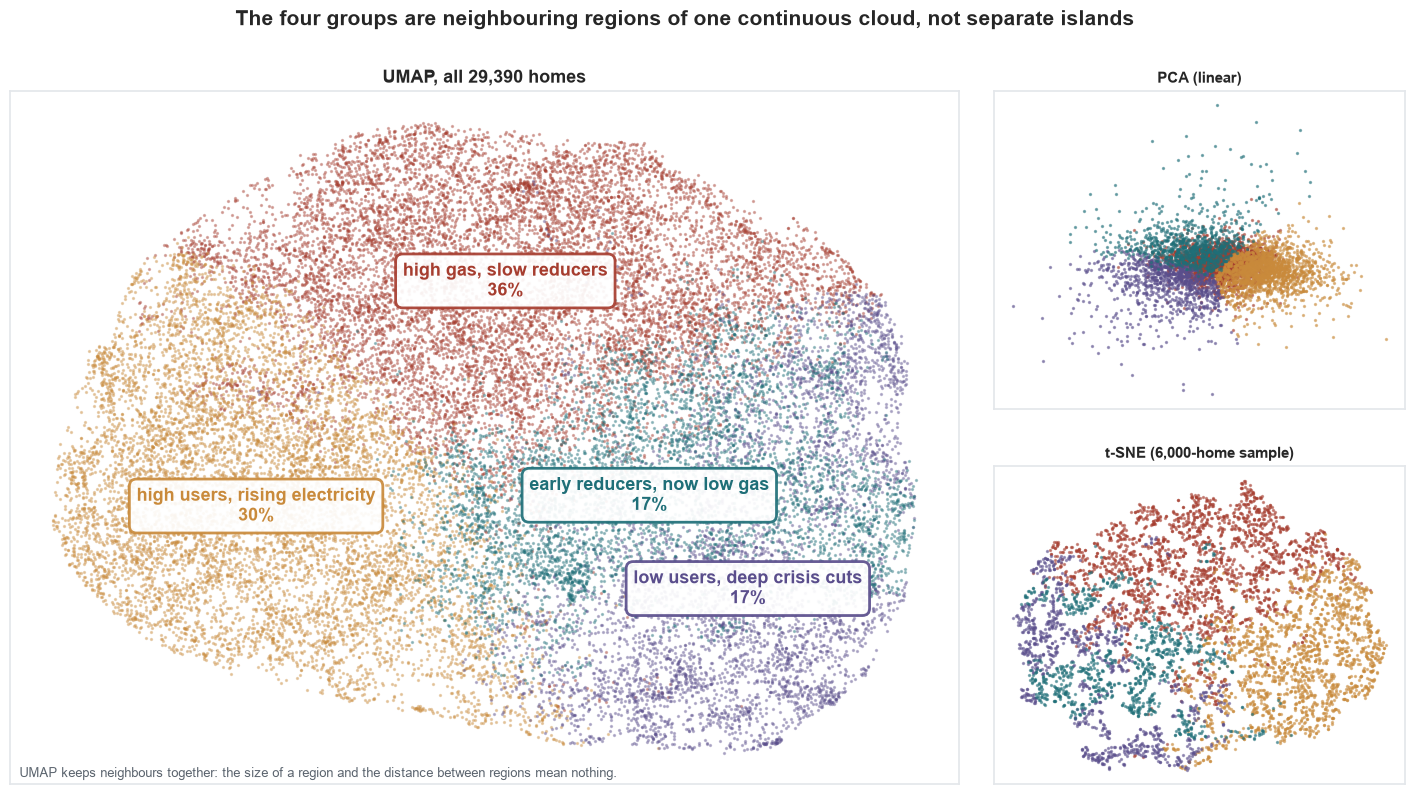

In [26]:
fig = plt.figure(figsize=(18, 9))
grid = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.9], wspace=0.08, hspace=0.18)
big = fig.add_subplot(grid[:, :2])
small = [fig.add_subplot(grid[0, 2]), fig.add_subplot(grid[1, 2])]

for name in ORDER:
    m = (df["cluster_name"] == name).to_numpy()
    big.scatter(umap_xy[m, 0], umap_xy[m, 1], s=2, alpha=0.35, color=CLUSTER_COLORS[name])
for name in ORDER:
    m = (df["cluster_name"] == name).to_numpy()
    x, y = np.median(umap_xy[m], axis=0)
    big.text(x, y, f"{name}\n{SHARE[name]:.0%}", ha="center", va="center", fontsize=13, fontweight="bold",
             color=CLUSTER_COLORS[name],
             bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=CLUSTER_COLORS[name], linewidth=2, alpha=0.92))
big.set_title(f"UMAP, all {len(df):,} homes", fontsize=13)
big.text(0.01, 0.01, "UMAP keeps neighbours together: the size of a region and the distance between regions mean nothing.",
         transform=big.transAxes, fontsize=9, color=MUTED_INK)

sample_names = df["cluster_name"].to_numpy()[SAMPLE]
for ax, (title, xy) in zip(small, [("PCA (linear)", pca_xy[SAMPLE]), ("t-SNE (6,000-home sample)", tsne_xy)]):
    for name in ORDER:
        m = sample_names == name
        ax.scatter(xy[m, 0], xy[m, 1], s=2, alpha=0.5, color=CLUSTER_COLORS[name])
    ax.set_title(title, fontsize=11)
for ax in [big] + small:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("The four groups are neighbouring regions of one continuous cloud, not separate islands",
             fontweight="bold", fontsize=15, y=0.97)
save("11_named_clusters_projections.png")
plt.show()

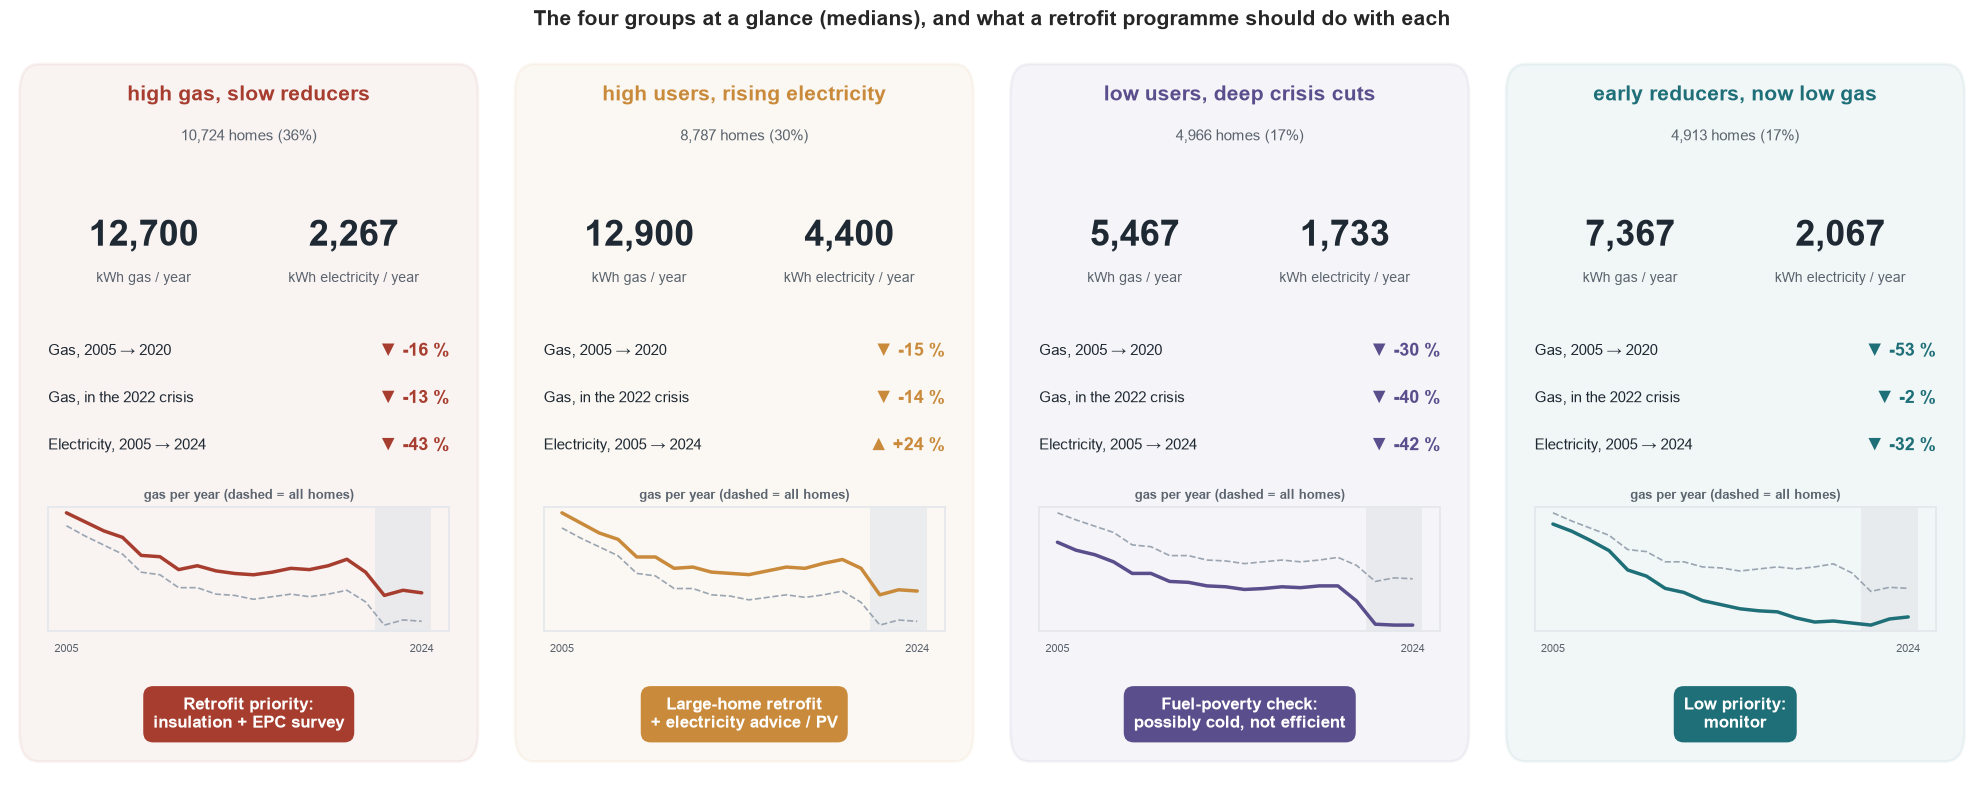

In [27]:
from matplotlib.patches import FancyBboxPatch

fig, axes = plt.subplots(1, 4, figsize=(20, 8))
for ax, name in zip(axes, ORDER):
    color = CLUSTER_COLORS[name]
    part = df[df["cluster_name"] == name]
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    ax.add_patch(FancyBboxPatch((0.02, 0.02), 0.96, 0.96, boxstyle="round,pad=0,rounding_size=0.04",
                                facecolor=color, alpha=0.06, edgecolor=color, linewidth=2))
    ax.text(0.5, 0.93, name, ha="center", fontsize=15, fontweight="bold", color=color)
    ax.text(0.5, 0.875, f"{len(part):,} homes ({SHARE[name]:.0%})", ha="center", fontsize=11, color=MUTED_INK)
    for x, value, unit in [(0.28, part["gas_recent_kwh"].median(), "kWh gas / year"),
                           (0.72, part["elec_recent_kwh"].median(), "kWh electricity / year")]:
        ax.text(x, 0.73, f"{value:,.0f}", ha="center", fontsize=26, fontweight="bold", color=INK)
        ax.text(x, 0.68, unit, ha="center", fontsize=10, color=MUTED_INK)
    rows = [("Gas, 2005 → 2020", CHANGE["gas_change_long"][name]),
            ("Gas, in the 2022 crisis", CHANGE["gas_change_crisis"][name]),
            ("Electricity, 2005 → 2024", CHANGE["elec_change_long"][name])]
    for j, (label, value) in enumerate(rows):
        y = 0.585 - j * 0.065
        ax.text(0.08, y, label, fontsize=11, color=INK, va="center")
        ax.text(0.92, y, f"{'▲' if value > 0 else '▼'} {value:+.0f} %", fontsize=13, fontweight="bold",
                color=color, ha="right", va="center")
    spark = ax.inset_axes([0.08, 0.2, 0.84, 0.17])
    spark.plot(YEARS, gas_c.median(), color="#9AA5B1", linestyle="--", linewidth=1.2)
    spark.plot(YEARS, gas_c[df["cluster_name"] == name].median(), color=color, linewidth=2.5)
    spark.axvspan(2021.5, 2024.5, color=GRID, alpha=0.7, linewidth=0)
    spark.set_xticks([2005, 2024]); spark.set_yticks([])
    spark.tick_params(labelsize=8)
    spark.set_facecolor("none")
    spark.set_title("gas per year (dashed = all homes)", fontsize=9, color=MUTED_INK)
    spark.grid(False)
    ax.text(0.5, 0.085, ACTIONS[name], ha="center", va="center", fontsize=12, fontweight="bold", color="white",
            bbox=dict(boxstyle="round,pad=0.6", facecolor=color, edgecolor="none"))
fig.suptitle("The four groups at a glance (medians), and what a retrofit programme should do with each",
             fontweight="bold", fontsize=15, y=0.98)
plt.tight_layout()
save("12_cluster_profile_card.png")
plt.show()

# 6. Save and reuse the model

The final model is the whole pipeline `StandardScaler → KMeans(k=4)`. K-Means has a `.predict()` method, so no separate "assigner" is needed. The model expects the **five engineered features** (formulas in section 1.2 and in the model card).

In [28]:
import sklearn
model_path = MODEL_DIR / "model.joblib"
joblib.dump(final_model, model_path)
print(f"Saved {model_path} ({model_path.stat().st_size / 1024:.0f} KB) with scikit-learn {sklearn.__version__}")

reloaded = joblib.load(model_path)
assert (reloaded.predict(df[FEATURES]) == df["cluster"]).all()


def features_from_kwh(gas_2005_08, gas_2019_21, gas_2022_24, elec_2005_08, elec_2022_24):
    # Turn five average annual readings (kWh) into the five model inputs
    return pd.DataFrame([{
        "log_gas_recent": np.log10(gas_2022_24),
        "log_elec_recent": np.log10(elec_2022_24),
        "gas_change_long": np.log2(gas_2019_21 / gas_2005_08),
        "gas_change_crisis": np.log2(gas_2022_24 / gas_2019_21),
        "elec_change_long": np.log2(elec_2022_24 / elec_2005_08),
    }])


# A hand-made example: a detached house that still burns 19,000 kWh of gas, barely changed since 2005
example = features_from_kwh(gas_2005_08=20000, gas_2019_21=19500, gas_2022_24=18500,
                            elec_2005_08=4200, elec_2022_24=4000)
cluster = reloaded.predict(example)[0]
print(f"\nExample home -> cluster {cluster}: '{CLUSTER_NAMES[cluster]}'")
example.round(3)

Saved ../models/model.joblib (117 KB) with scikit-learn 1.9.1

Example home -> cluster 0: 'high users, rising electricity'


,log_gas_recent,log_elec_recent,gas_change_long,gas_change_crisis,elec_change_long
0,4.267,3.602,-0.037,-0.076,-0.07


# 7. Export the clustered dataset

The published table has one row per home with: the cleaned building characteristics, the **yearly valid readings** used, the window averages and the five engineered features, the **cluster** and its **name**, the Ward label for the 6,000 sampled homes (`cluster_ward`, empty otherwise), the DBSCAN outlier flag for the sample, and the **PCA and UMAP coordinates** (t-SNE was only computed for the sample, so `tsne_x/y` are filled for those 6,000 homes).

In [29]:
final = pd.DataFrame({
    "home_id": np.arange(len(df)),
    "prop_type": df["PROP_TYPE"], "prop_age_band": df["PROP_AGE_BAND"], "floor_area_band": df["FLOOR_AREA_BAND"],
    "council_tax_band": df["COUNCIL_TAX_BAND"], "imd_band": df["imd_band"].astype("Int64"),
    "region": df["REGION"], "region_name": df["region_name"], "epc": df["EPC"],
    "cwi_flag": df["CWI_FLAG"], "li_flag": df["LI_FLAG"], "pv_flag": df["PV_FLAG"],
})
for y in YEARS:
    final[f"gas_{y}"] = gas_c[y].to_numpy()
for y in YEARS:
    final[f"elec_{y}"] = elec_c[y].to_numpy()
for col in ["gas_early_kwh", "gas_pre_kwh", "gas_recent_kwh", "elec_early_kwh", "elec_recent_kwh"] + FEATURES:
    final[col] = df[col].round(4)
final["cluster"] = df["cluster"]
final["cluster_name"] = df["cluster_name"]
final["cluster_ward"] = pd.Series(pd.NA, index=final.index, dtype="Int64")
final.loc[SAMPLE, "cluster_ward"] = ward_labels
final["dbscan_outlier"] = pd.Series(pd.NA, index=final.index, dtype="boolean")
final.loc[SAMPLE, "dbscan_outlier"] = is_noise
final["pca_x"], final["pca_y"] = pca_xy[:, 0].round(4), pca_xy[:, 1].round(4)
final["umap_x"], final["umap_y"] = umap_xy[:, 0].round(4), umap_xy[:, 1].round(4)
final["tsne_x"] = np.nan
final["tsne_y"] = np.nan
final.loc[SAMPLE, "tsne_x"], final.loc[SAMPLE, "tsne_y"] = tsne_xy[:, 0].round(4), tsne_xy[:, 1].round(4)

dataset_path = DATASET_DIR / "need_household_energy_trajectories.csv"
final.to_csv(dataset_path, index=False)
print(f"Saved {dataset_path}: {final.shape[0]:,} rows x {final.shape[1]} columns ({dataset_path.stat().st_size / 1e6:.1f} MB)")

# Figures shown in the dataset card
for name in ["09_trajectories_per_cluster.png", "11_named_clusters_projections.png", "12_cluster_profile_card.png"]:
    (DATASET_DIR / name).write_bytes((FIG_DIR / name).read_bytes())
final.head(3)

Saved ../dataset/need_household_energy_trajectories.csv: 29,390 rows x 72 columns (14.4 MB)


,home_id,prop_type,prop_age_band,floor_area_band,council_tax_band,imd_band,region,region_name,epc,cwi_flag,li_flag,pv_flag,gas_2005,gas_2006,gas_2007,gas_2008,gas_2009,gas_2010,gas_2011,gas_2012,...,gas_early_kwh,gas_pre_kwh,gas_recent_kwh,elec_early_kwh,elec_recent_kwh,log_gas_recent,log_elec_recent,gas_change_long,gas_change_crisis,elec_change_long,cluster,cluster_name,cluster_ward,dbscan_outlier,pca_x,pca_y,umap_x,umap_y,tsne_x,tsne_y
0,0,Semi detached,3,2,A,3,E12000004,East Midlands,C,0,0,0,NaN,NaN,16000.0,13400.0,12800.0,12400.0,10800.0,12100.0,...,14700.0,7133.3333,6050.0000,2033.3333,2866.6667,3.7818,3.4574,-1.0432,-0.2376,0.4955,2,"early reducers, now low gas",2,False,-0.1364,0.1036,4.6973,3.4156,-3.381,-39.734901
1,1,Mid terrace,1,3,E,1,E12000007,London,No EPC,0,0,0,16600.0,16600.0,18300.0,18200.0,16600.0,18000.0,16800.0,16600.0,...,17425.0,15933.3333,13366.6667,4325.0000,2733.3333,4.1260,3.4367,-0.1291,-0.2534,-0.6620,3,"high gas, slow reducers",<NA>,<NA>,0.3309,-0.0244,4.1316,8.3597,NaN,NaN
2,2,Bungalow,2,2,D,5,E12000008,South East,D,0,1,0,27500.0,14400.0,11300.0,13200.0,12000.0,12100.0,12800.0,12100.0,...,16600.0,14133.3333,11750.0000,3675.0000,1900.0000,4.0700,3.2788,-0.2321,-0.2664,-0.9517,3,"high gas, slow reducers",<NA>,<NA>,-0.3908,0.1184,6.3463,8.8145,NaN,NaN


# 8. Conclusions

### Key findings
- **Household energy behaviour is a continuum.** PCA needs 4 of 5 dimensions for 95 % of the variance, t-SNE and UMAP show one connected cloud, DBSCAN finds a single dense cluster (+ 7 % outliers) and the silhouette never exceeds 0.22. Clusters here are a **useful cut**, not natural species.
- **The cut is reproducible.** K-Means with k = 4 gives the same groups across seeds (ARI ≈ 0.98) and 80 % subsamples (ARI ≥ 0.94). Ward cuts the same cloud differently (ARI 0.27), so the borders are a modelling choice.
- **Two high-use groups make up two thirds of the homes**: *high gas, slow reducers* (36 %, ~12,700 kWh gas, only −16 % in 15 years, the fewest EPC A–C ratings) and *high users, rising electricity* (30 %, the only group whose electricity rose, +24 %).
- **Two low-use groups got there in opposite ways**: *early reducers* (17 %) halved their gas steadily before 2021 and have the most insulation; *deep crisis cuts* (17 %) dropped 40 % in one year, 2022, and live in the most deprived areas, which points to **under-heating** rather than efficiency.
- **For a retrofit programme**: target the *slow reducers* for insulation, check the *deep crisis cuts* group for fuel poverty, and treat the *early reducers* as largely done.

### Limitations and biases
- **Sample:** gas-heated homes in England and Wales with valid readings in all three windows (29,390 of 40,445): homes built or connected after 2008, and electrically heated homes, are excluded.
- **Annual data only:** we see *how much* and *how it changed*, not *when in the day*; changes in occupancy (a new family, an empty year) look the same as efficiency changes. The DBSCAN outlier flag marks the most extreme of these.
- **Readings are rounded** (to 100 kWh) and flagged values were removed, which leaves gaps and creates artificial clumps in t-SNE.
- **Choices matter:** other windows, other features (e.g. adding floor area) or another k would draw other borders. The groups are weakly separated (silhouette ≈ 0.18): use them for **programme targeting at group level**, not to judge individual households.
- The interpretation of "deep crisis cuts" as rationing is a **hypothesis** consistent with deprivation and timing; it needs survey data to confirm.
- Not to be used outside England and Wales, for non-gas homes, or as a prediction of future consumption.